# c3 CMB magnification bias α — results

Loads the c3 CMB measurements written by `calculate_magnification_bias_c3.py` (`configs/c3_photo.ini`, `configs/c3_spec.ini`) from `measurements/v2/c3cmb/` and

1. tabulates α ± σ and the slope `s = 0.4·α` per sample and weight option, for the full footprint and the CMB-lensing footprints, and writes the full table to a CSV;
2. plots how much the weights change α.

Files: one per galaxy type × weight option, `DESI_magnification_bias_c3_<galaxy_type>_<weight>.h5`, nested `sample/region/{alphas, alphas_error, simple_alphas, simple_alphas_error, N_galaxies}` (one-element arrays) plus a `metadata` group with each sample's z-range. `alphas` is the stepwise-fit estimate (the headline result).

In [1]:
import numpy as np
import h5py
import pandas as pd
import matplotlib.pyplot as plt

## Configuration

Galaxy types and their weight options, as in the two c3 configs. Weight labels:
- photo: `none`; `weight_phot` = `Z_WEIGHT·WEIGHT_IMLIN` (Clgg weighting); `weight_phot_kernel` = `Z_WEIGHT·KERNEL_WEIGHT_KAPPA·WEIGHT_IMLIN` (Clkg weighting)
- spec: `none`; `weight_FKP` = `WEIGHT·WEIGHT_FKP` (full c3 weight, WEIGHT = COMP·SYS·ZFAIL)

In [2]:
RESULTS_DIR = "/global/cfs/cdirs/desi/users/schiarenza/magnification_bias_DESI/measurements/v2/c3cmb/"

GALAXY_TYPES = {
    # galaxy_type: (kind, weight options)
    "BGS_phot":         ("photo", ["none", "weight_phot", "weight_phot_kernel"]),
    "LRG_phot":         ("photo", ["none", "weight_phot", "weight_phot_kernel"]),
    "BGS_BRIGHT-21.35": ("spec",  ["none", "weight_FKP"]),
    "LRG":              ("spec",  ["none", "weight_FKP"]),
    "ELG_LOPnotqso":    ("spec",  ["none", "weight_FKP"]),
    "QSO":              ("spec",  ["none", "weight_FKP"]),
}
WEIGHT_LABELS = {
    "none": "no weights",
    "weight_phot": "Z_WEIGHT·IMLIN",
    "weight_phot_kernel": "Z_WEIGHT·KERNEL·IMLIN",
    "weight_FKP": "WEIGHT·WEIGHT_FKP",
}
HEADLINE_REGIONS = ["all", "act", "planck"]

## Load everything into one flat table

One row per (kind, sample, region, weight).

In [3]:
rows = []
for galaxy_type, (kind, weights) in GALAXY_TYPES.items():
    for weight in weights:
        fname = RESULTS_DIR + f"DESI_magnification_bias_c3_{galaxy_type}_{weight}.h5"
        with h5py.File(fname, "r") as f:
            meta = f["metadata"]
            for sample in f:
                if sample == "metadata":
                    continue
                zmin, zmax = meta[f"{sample}_zrange"][()]
                for region in f[sample]:
                    g = f[sample][region]
                    rows.append({
                        "kind": kind, "galaxy_type": galaxy_type, "sample": sample,
                        "zmin": zmin, "zmax": zmax, "region": region, "weight": weight,
                        "alpha": g["alphas"][0], "alpha_error": g["alphas_error"][0],
                        "simple_alpha": g["simple_alphas"][0], "simple_alpha_error": g["simple_alphas_error"][0],
                        "N_galaxies": int(g["N_galaxies"][0]),
                    })
df = pd.DataFrame(rows)
df["s"] = 0.4 * df["alpha"]
df["s_error"] = 0.4 * df["alpha_error"]
print(f"{len(df)} measurements")
df.head()

292 measurements


,kind,galaxy_type,sample,zmin,zmax,region,weight,alpha,alpha_error,simple_alpha,simple_alpha_error,N_galaxies,s,s_error
0,photo,BGS_phot,BGS,0.15,0.4,GAL040,none,1.394648,0.003803,1.395727,0.003287,6457925,0.557859,0.001521
1,photo,BGS_phot,BGS,0.15,0.4,NGC,none,1.404416,0.004584,1.403724,0.003962,4470359,0.561766,0.001834
2,photo,BGS_phot,BGS,0.15,0.4,SGC,none,1.391134,0.005000,1.392529,0.004322,3728252,0.556454,0.002000
3,photo,BGS_phot,BGS,0.15,0.4,act,none,1.391723,0.004992,1.394950,0.004315,3745474,0.556689,0.001997
4,photo,BGS_phot,BGS,0.15,0.4,all,none,1.398393,0.003379,1.398633,0.002921,8198611,0.559357,0.001352


## Headline tables

α ± σ (stepwise fit) per sample and weight option, for the full footprint and the ACT / Planck lensing footprints — one table for the photometric samples, one for the spectroscopic ones (they have different weight options). `s = 0.4·α` tables follow.

In [4]:
SAMPLE_ORDER = ["BGS", "LRG1", "LRG2", "LRG3", "ELG", "QSO", "QSO1", "QSO2"]
WEIGHT_ORDER = ["none", "weight_phot", "weight_phot_kernel", "weight_FKP"]

def headline_table(kind, value="alpha"):
    sub = df[(df["kind"] == kind) & df["region"].isin(HEADLINE_REGIONS)].copy()
    sub["entry"] = [f"{v:.3f} ± {e:.3f}" for v, e in zip(sub[value], sub[value + "_error"])]
    weights = [w for w in WEIGHT_ORDER if w in set(sub["weight"])]
    sub["weight"] = pd.Categorical(sub["weight"].map(WEIGHT_LABELS), [WEIGHT_LABELS[w] for w in weights])
    sub["sample"] = pd.Categorical(sub["sample"], [s for s in SAMPLE_ORDER if s in set(sub["sample"])])
    sub["region"] = pd.Categorical(sub["region"], HEADLINE_REGIONS)
    return sub.pivot_table(index="sample", columns=["region", "weight"], values="entry",
                           aggfunc="first", observed=True).sort_index().sort_index(axis=1)

print("Photometric samples: alpha")
display(headline_table("photo"))
print("Spectroscopic samples: alpha")
display(headline_table("spec"))

Photometric samples: alpha


region            all                                                 act  \
weight     no weights Z_WEIGHT·IMLIN Z_WEIGHT·KERNEL·IMLIN     no weights   
sample                                                                      
BGS     1.398 ± 0.003  1.972 ± 0.006         1.959 ± 0.007  1.392 ± 0.005   
LRG1    2.471 ± 0.010  2.525 ± 0.010         2.593 ± 0.011  2.430 ± 0.015   
LRG2    2.583 ± 0.008  2.679 ± 0.008         2.424 ± 0.009  2.566 ± 0.012   
LRG3    2.049 ± 0.006  2.390 ± 0.008         2.382 ± 0.007  2.068 ± 0.009   

region                                              planck                 \
weight Z_WEIGHT·IMLIN Z_WEIGHT·KERNEL·IMLIN     no weights Z_WEIGHT·IMLIN   
sample                                                                      
BGS     1.963 ± 0.009         1.950 ± 0.010  1.400 ± 0.003  1.974 ± 0.007   
LRG1    2.488 ± 0.015         2.549 ± 0.016  2.470 ± 0.010  2.525 ± 0.010   
LRG2    2.663 ± 0.012         2.411 ± 0.013  2.580 ± 0.008  2.677 ± 0.008   
LRG3    2.401 ± 0.012         2.366 ± 0.011  2.049 ± 0.006  2.391 ± 0.008   

region                        
weight Z_WEIGHT·KERNEL·IMLIN  
sample                        
BGS            1.961 ± 0.007  
LRG1           2.592 ± 0.011  
LRG2           2.423 ± 0.009  
LRG3           2.382 ± 0.007

Spectroscopic samples: alpha


region            all                              act                    \
weight     no weights WEIGHT·WEIGHT_FKP     no weights WEIGHT·WEIGHT_FKP   
sample                                                                     
BGS     2.434 ± 0.012     2.377 ± 0.013  2.378 ± 0.019     2.332 ± 0.021   
LRG1    2.550 ± 0.013     2.534 ± 0.014  2.528 ± 0.019     2.513 ± 0.020   
LRG2    2.385 ± 0.010     2.376 ± 0.011  2.385 ± 0.015     2.382 ± 0.016   
LRG3    2.192 ± 0.009     2.306 ± 0.011  2.186 ± 0.013     2.296 ± 0.016   
ELG     1.516 ± 0.005     1.520 ± 0.007  1.516 ± 0.008     1.516 ± 0.009   
QSO     0.242 ± 0.003     0.250 ± 0.004  0.238 ± 0.005     0.246 ± 0.006   
QSO1    0.172 ± 0.004     0.178 ± 0.004  0.163 ± 0.006     0.166 ± 0.006   
QSO2    0.342 ± 0.006     0.351 ± 0.007  0.346 ± 0.010     0.359 ± 0.010   

region         planck                    
weight     no weights WEIGHT·WEIGHT_FKP  
sample                                   
BGS     2.435 ± 0.012     2.379 ± 0.013  
LRG1    2.549 ± 0.013     2.532 ± 0.014  
LRG2    2.381 ± 0.010     2.373 ± 0.011  
LRG3    2.191 ± 0.009     2.305 ± 0.011  
ELG     1.518 ± 0.005     1.523 ± 0.007  
QSO     0.243 ± 0.004     0.251 ± 0.004  
QSO1    0.172 ± 0.004     0.177 ± 0.004  
QSO2    0.344 ± 0.006     0.353 ± 0.007

In [5]:
# s = 0.4·α for the same entries (the magnification-bias slope used downstream)
print("Photometric samples: s")
display(headline_table("photo", value="s"))
print("Spectroscopic samples: s")
display(headline_table("spec", value="s"))

Photometric samples: s


region            all                                                 act  \
weight     no weights Z_WEIGHT·IMLIN Z_WEIGHT·KERNEL·IMLIN     no weights   
sample                                                                      
BGS     0.559 ± 0.001  0.789 ± 0.003         0.783 ± 0.003  0.557 ± 0.002   
LRG1    0.988 ± 0.004  1.010 ± 0.004         1.037 ± 0.004  0.972 ± 0.006   
LRG2    1.033 ± 0.003  1.072 ± 0.003         0.969 ± 0.004  1.026 ± 0.005   
LRG3    0.820 ± 0.003  0.956 ± 0.003         0.953 ± 0.003  0.827 ± 0.004   

region                                              planck                 \
weight Z_WEIGHT·IMLIN Z_WEIGHT·KERNEL·IMLIN     no weights Z_WEIGHT·IMLIN   
sample                                                                      
BGS     0.785 ± 0.004         0.780 ± 0.004  0.560 ± 0.001  0.790 ± 0.003   
LRG1    0.995 ± 0.006         1.020 ± 0.006  0.988 ± 0.004  1.010 ± 0.004   
LRG2    1.065 ± 0.005         0.965 ± 0.005  1.032 ± 0.003  1.071 ± 0.003   
LRG3    0.960 ± 0.005         0.947 ± 0.004  0.820 ± 0.003  0.956 ± 0.003   

region                        
weight Z_WEIGHT·KERNEL·IMLIN  
sample                        
BGS            0.784 ± 0.003  
LRG1           1.037 ± 0.004  
LRG2           0.969 ± 0.004  
LRG3           0.953 ± 0.003

Spectroscopic samples: s


region            all                              act                    \
weight     no weights WEIGHT·WEIGHT_FKP     no weights WEIGHT·WEIGHT_FKP   
sample                                                                     
BGS     0.973 ± 0.005     0.951 ± 0.005  0.951 ± 0.008     0.933 ± 0.008   
LRG1    1.020 ± 0.005     1.014 ± 0.005  1.011 ± 0.008     1.005 ± 0.008   
LRG2    0.954 ± 0.004     0.951 ± 0.004  0.954 ± 0.006     0.953 ± 0.006   
LRG3    0.877 ± 0.004     0.922 ± 0.004  0.874 ± 0.005     0.918 ± 0.006   
ELG     0.606 ± 0.002     0.608 ± 0.003  0.606 ± 0.003     0.607 ± 0.004   
QSO     0.097 ± 0.001     0.100 ± 0.001  0.095 ± 0.002     0.099 ± 0.002   
QSO1    0.069 ± 0.002     0.071 ± 0.002  0.065 ± 0.002     0.066 ± 0.002   
QSO2    0.137 ± 0.003     0.140 ± 0.003  0.139 ± 0.004     0.144 ± 0.004   

region         planck                    
weight     no weights WEIGHT·WEIGHT_FKP  
sample                                   
BGS     0.974 ± 0.005     0.951 ± 0.005  
LRG1    1.020 ± 0.005     1.013 ± 0.006  
LRG2    0.953 ± 0.004     0.949 ± 0.004  
LRG3    0.877 ± 0.004     0.922 ± 0.004  
ELG     0.607 ± 0.002     0.609 ± 0.003  
QSO     0.097 ± 0.001     0.100 ± 0.001  
QSO1    0.069 ± 0.002     0.071 ± 0.002  
QSO2    0.138 ± 0.003     0.141 ± 0.003

## Export the full table to CSV

Every sample × region × weight option (incl. z-range, N, simple estimate and s), written next to the HDF5 files so it can be shared together with them.

In [6]:
csv_path = RESULTS_DIR + "c3_alpha_summary.csv"
(df.assign(sample=pd.Categorical(df["sample"], SAMPLE_ORDER))
   .sort_values(["kind", "sample", "region", "weight"], ascending=[True, True, True, True])
   .to_csv(csv_path, index=False, float_format="%.5f"))
print("wrote", csv_path)

wrote /global/cfs/cdirs/desi/users/schiarenza/magnification_bias_DESI/measurements/v2/c3cmb/c3_alpha_summary.csv


## How much do the weights change α?

One footprint at a time (`REGION`, default `all` — set it to `act` or `planck` for the CMB-lensing footprints). Columns: photometric samples (no weights, the redshift re-weight, and the redshift re-weight with the lensing-kernel weight) and spectroscopic samples (no weights vs. the full c3 weight).

- **Top row:** α for each weight option (1σ error bars, mostly smaller than the markers).
- **Bottom row:** the shift Δα = α(weighted) − α(no weights). The error bar is the σ of the weighted estimate; the weighted and unweighted estimates use the same galaxies and are strongly correlated, so it overstates the uncertainty on Δα — shifts well outside it are certainly real.

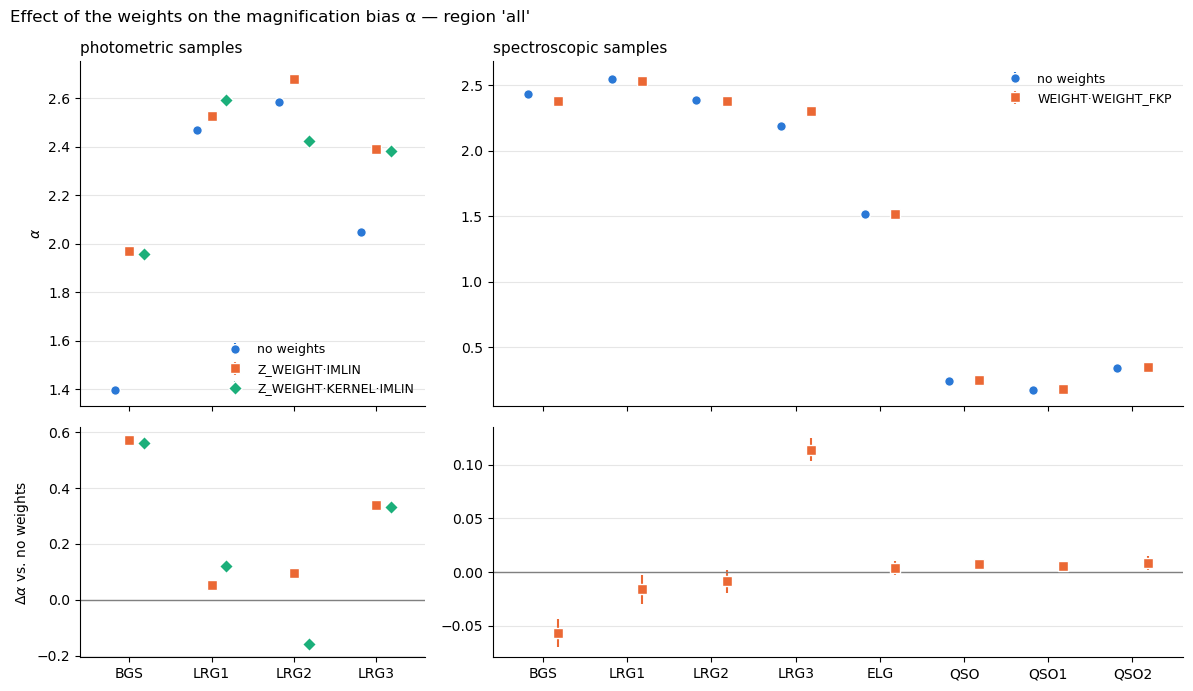

In [7]:
REGION = "all"

# fixed colour + marker per weight option (marker = secondary encoding, colour-blind safe)
STYLE = {
    "none":               dict(color="#2a78d6", marker="o"),
    "weight_phot":        dict(color="#eb6834", marker="s"),
    "weight_FKP":         dict(color="#eb6834", marker="s"),
    "weight_phot_kernel": dict(color="#1baf7a", marker="D"),
}

def style_axis(ax):
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col",
                         gridspec_kw={"width_ratios": [4, 8], "height_ratios": [3, 2]})
for col, kind in enumerate(["photo", "spec"]):
    sub = df[(df["kind"] == kind) & (df["region"] == REGION)]
    samples = [s for s in SAMPLE_ORDER if s in set(sub["sample"])]
    weights = [w for w in WEIGHT_ORDER if w in set(sub["weight"])]
    x = np.arange(len(samples))
    offsets = np.linspace(-0.18, 0.18, len(weights))
    base = sub[sub["weight"] == "none"].set_index("sample").loc[samples]
    marker_kw = dict(linestyle="none", markersize=7, elinewidth=1.5, capsize=0,
                     markeredgecolor="white", markeredgewidth=1.0)
    for off, w in zip(offsets, weights):
        sw = sub[sub["weight"] == w].set_index("sample").loc[samples]
        axes[0, col].errorbar(x + off, sw["alpha"], yerr=sw["alpha_error"],
                              label=WEIGHT_LABELS[w], **marker_kw, **STYLE[w])
        if w != "none":
            axes[1, col].errorbar(x + off, sw["alpha"] - base["alpha"], yerr=sw["alpha_error"],
                                  **marker_kw, **STYLE[w])
    axes[1, col].axhline(0, color="0.5", linewidth=1)
    axes[1, col].set_xticks(x)
    axes[1, col].set_xticklabels(samples)
    axes[1, col].set_xlim(-0.6, len(samples) - 0.4)
    axes[0, col].set_title("photometric samples" if kind == "photo" else "spectroscopic samples",
                           loc="left", fontsize=11)
    axes[0, col].legend(frameon=False, fontsize=9, loc="best")
    for ax in axes[:, col]:
        style_axis(ax)
axes[0, 0].set_ylabel(r"$\alpha$")
axes[1, 0].set_ylabel(r"$\Delta\alpha$ vs. no weights")
fig.suptitle(f"Effect of the weights on the magnification bias α — region '{REGION}'",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

In [8]:
# the same comparison as numbers: shift relative to no weights, in units of σ
shift = (df[df["region"] == REGION]
           .pivot_table(index=["kind", "sample"], columns="weight", values=["alpha", "alpha_error"], observed=True))
rows = []
for (kind, sample), r in shift.iterrows():
    for w in WEIGHT_ORDER[1:]:
        if ("alpha", w) in r and not np.isnan(r[("alpha", w)]):
            d = r[("alpha", w)] - r[("alpha", "none")]
            rows.append({"kind": kind, "sample": sample, "weight": WEIGHT_LABELS[w],
                         "Δα vs none": round(d, 3), "Δα / σ": round(d / r[("alpha_error", w)], 1)})
pd.DataFrame(rows).set_index(["kind", "sample", "weight"]).sort_index(level="kind", sort_remaining=False)

Δα vs none  Δα / σ
kind  sample weight                                   
photo BGS    Z_WEIGHT·IMLIN              0.574    89.8
             Z_WEIGHT·KERNEL·IMLIN       0.560    83.7
      LRG1   Z_WEIGHT·IMLIN              0.054     5.4
             Z_WEIGHT·KERNEL·IMLIN       0.122    11.4
      LRG2   Z_WEIGHT·IMLIN              0.096    11.6
             Z_WEIGHT·KERNEL·IMLIN      -0.159   -18.1
      LRG3   Z_WEIGHT·IMLIN              0.340    43.2
             Z_WEIGHT·KERNEL·IMLIN       0.332    45.2
spec  BGS    WEIGHT·WEIGHT_FKP          -0.056    -4.3
      ELG    WEIGHT·WEIGHT_FKP           0.004     0.6
      LRG1   WEIGHT·WEIGHT_FKP          -0.016    -1.2
      LRG2   WEIGHT·WEIGHT_FKP          -0.008    -0.8
      LRG3   WEIGHT·WEIGHT_FKP           0.114    10.4
      QSO    WEIGHT·WEIGHT_FKP           0.007     2.0
      QSO1   WEIGHT·WEIGHT_FKP           0.005     1.3
      QSO2   WEIGHT·WEIGHT_FKP           0.009     1.3

## What drives α? Contribution of each selection cut

From the `_individual_cuts.h5` files: each cut is applied on its own to the ±κ-lensed catalogue (κ = 0.01, the simple estimator), giving that cut's contribution to α. Raw cut names are grouped by physical role so each group keeps one colour across samples (see `CUT_GROUPS`; anything unlisted goes to "other cuts"). Positive contributions stack upward, negative ones downward. The black tick is the simple α of the full selection; the stacked sum can exceed it slightly, because an object near two thresholds counts in both.

Weight option per kind and footprint are set below (default: the auto-spectrum weights, full footprint).

In [9]:
CUT_REGION = "all"
CUT_WEIGHT = {"photo": "weight_phot", "spec": "weight_FKP"}

# raw cut name -> physical group (one fixed colour per group)
CUT_GROUPS = {
    "r < 19.5": "faint flux limit",
    "faint limit": "faint flux limit",                    # LRG z_fiber < 21.6 (21.61 north)
    "faint cut": "faint flux limit",                      # ELG g_fiber limit
    "fiberflux_r < 21.0": "fiber-magnitude limit",        # BGS_phot observed r_fiber < 21
    "double sliding cuts and high-z extension": "colour / sliding cuts",
    "low-z cuts": "colour / sliding cuts",
    "non-stellar cut": "colour / sliding cuts",
    "absolute magnitude cuts": "absolute-magnitude cut",
    "deltachi2_cut": "redshift-quality cut",              # DELTACHI2 (BGS, LRG) / o2c (ELG)
    "redshift bin cut": "photo-z bin edges",              # LRG_phot: photo-z shifts under lensing
    "QSO cuts": "QSO selection",
}
GROUP_ORDER = ["faint flux limit", "fiber-magnitude limit", "colour / sliding cuts", "absolute-magnitude cut",
               "redshift-quality cut", "photo-z bin edges", "QSO selection", "other cuts"]
GROUP_COLORS = dict(zip(GROUP_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                      "#e87ba4", "#008300", "#6250d6", "#e34948"]))

cut_rows = []
for galaxy_type, (kind, _) in GALAXY_TYPES.items():
    weight = CUT_WEIGHT[kind]
    with h5py.File(RESULTS_DIR + f"DESI_magnification_bias_c3_{galaxy_type}_{weight}_individual_cuts.h5", "r") as f:
        for sample in f:
            for cut, ds in f[sample][CUT_REGION]["zbin_0"].items():
                alpha, alpha_err, lost_plus, lost_minus, n = ds[()]
                cut_rows.append({"kind": kind, "sample": sample, "cut": cut,
                                 "group": CUT_GROUPS.get(cut, "other cuts"),
                                 "alpha_cut": alpha, "alpha_cut_error": alpha_err,
                                 "lost_plus_kappa": int(lost_plus), "lost_minus_kappa": int(lost_minus)})
cuts = pd.DataFrame(cut_rows)

# table: non-negligible contributions, raw cut names
(cuts[cuts["alpha_cut"].abs() > 0.005]
     .assign(sample=lambda d: pd.Categorical(d["sample"], SAMPLE_ORDER))
     .sort_values(["kind", "sample", "alpha_cut"], ascending=[True, True, False])
     .set_index(["kind", "sample", "group", "cut"])
     .round(4))

alpha_cut  \
kind  sample group                  cut                                                   
photo BGS    faint flux limit       r < 19.5                                     1.5263   
             fiber-magnitude limit  fiberflux_r < 21.0                           0.4626   
      LRG1   colour / sliding cuts  double sliding cuts and high-z extension     2.4615   
             faint flux limit       faint limit                                  0.0549   
             photo-z bin edges      redshift bin cut                            -0.0182   
      LRG2   colour / sliding cuts  double sliding cuts and high-z extension     2.0870   
             photo-z bin edges      redshift bin cut                             0.2903   
             faint flux limit       faint limit                                  0.2874   
      LRG3   faint flux limit       faint limit                                  2.0352   
             colour / sliding cuts  double sliding cuts and high-z extension     0.3465   
             photo-z bin edges      redshift bin cut                            -0.0196   
spec  BGS    absolute-magnitude cut absolute magnitude cuts                      2.2777   
             faint flux limit       r < 19.5                                     0.1251   
             redshift-quality cut   deltachi2_cut                                0.0166   
      LRG1   colour / sliding cuts  double sliding cuts and high-z extension     2.4288   
             faint flux limit       faint limit                                  0.0608   
             redshift-quality cut   deltachi2_cut                                0.0288   
      LRG2   colour / sliding cuts  double sliding cuts and high-z extension     1.9449   
             faint flux limit       faint limit                                  0.3882   
             redshift-quality cut   deltachi2_cut                                0.0281   
      LRG3   faint flux limit       faint limit                                  1.8520   
             colour / sliding cuts  double sliding cuts and high-z extension     0.4190   
             redshift-quality cut   deltachi2_cut                                0.0290   
      ELG    faint flux limit       faint cut                                    1.5437   
             redshift-quality cut   deltachi2_cut                                0.0333   
             other cuts             remove quasars                              -0.0630   
      QSO    QSO selection          QSO cuts                                     0.2539   
      QSO1   QSO selection          QSO cuts                                     0.1822   
      QSO2   QSO selection          QSO cuts                                     0.3543   

                                                                              alpha_cut_error  \
kind  sample group                  cut                                                         
photo BGS    faint flux limit       r < 19.5                                           0.0035   
             fiber-magnitude limit  fiberflux_r < 21.0                                 0.0019   
      LRG1   colour / sliding cuts  double sliding cuts and high-z extension           0.0078   
             faint flux limit       faint limit                                        0.0012   
             photo-z bin edges      redshift bin cut                                   0.0035   
      LRG2   colour / sliding cuts  double sliding cuts and high-z extension           0.0058   
             photo-z bin edges      redshift bin cut                                   0.0030   
             faint flux limit       faint limit                                        0.0021   
      LRG3   faint flux limit       faint limit                                        0.0050   
             colour / sliding cuts  double sliding cuts and high-z extension           0.0021   
             photo-z bin edges      redshift bin cut                                   0.001

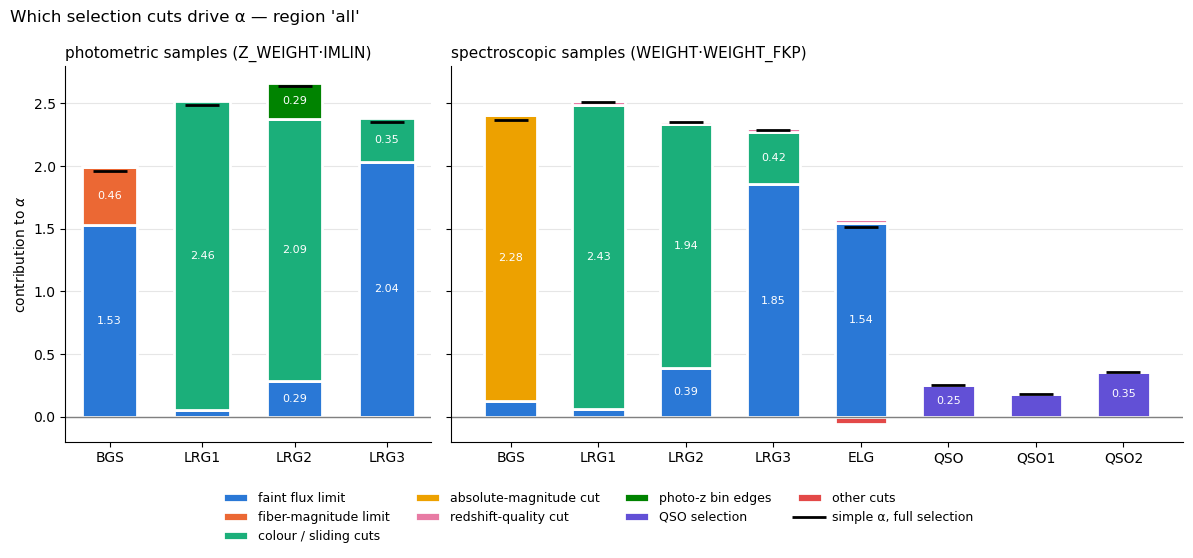

In [10]:
group_alpha = (cuts.groupby(["kind", "sample", "group"], observed=True)["alpha_cut"].sum()
                  .unstack("group").reindex(columns=GROUP_ORDER).fillna(0.0))
simple_total = (df[(df["region"] == CUT_REGION) & (df["weight"] == df["kind"].map(CUT_WEIGHT))]
                  .set_index(["kind", "sample"])["simple_alpha"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [4, 8]}, sharey=True)
used_groups = set()
for ax, kind in zip(axes, ["photo", "spec"]):
    samples = [s for s in SAMPLE_ORDER if (kind, s) in group_alpha.index]
    x = np.arange(len(samples))
    pos_base, neg_base = np.zeros(len(samples)), np.zeros(len(samples))
    for group in GROUP_ORDER:
        vals = np.array([group_alpha.loc[(kind, s), group] for s in samples])
        if np.all(np.abs(vals) < 0.005):
            continue
        used_groups.add(group)
        bottoms = np.where(vals >= 0, pos_base, neg_base)
        ax.bar(x, vals, bottom=bottoms, width=0.6, color=GROUP_COLORS[group],
               edgecolor="white", linewidth=2, label=group)
        for xi, v, b in zip(x, vals, bottoms):
            if abs(v) >= 0.25:   # direct-label the big segments
                ax.text(xi, b + v / 2, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white")
        pos_base += np.clip(vals, 0, None)
        neg_base += np.clip(vals, None, 0)
    totals = [simple_total.loc[(kind, s)] for s in samples]
    ax.scatter(x, totals, marker="_", s=600, color="black", linewidths=2, zorder=5,
               label="simple α, full selection")
    ax.axhline(0, color="0.5", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(samples)
    ax.set_title(("photometric samples" if kind == "photo" else "spectroscopic samples")
                 + f" ({WEIGHT_LABELS[CUT_WEIGHT[kind]]})", loc="left", fontsize=11)
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel(r"contribution to $\alpha$")
handles, labels = axes[1].get_legend_handles_labels()
h0, l0 = axes[0].get_legend_handles_labels()
legend = dict(zip(l0 + labels, h0 + handles))
order = [g for g in GROUP_ORDER if g in used_groups] + ["simple α, full selection"]
fig.legend([legend[k] for k in order], order, frameon=False, fontsize=9,
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f"Which selection cuts drive α — region '{CUT_REGION}'", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

## Photometric vs. spectroscopic samples

BGS and LRG1–3 measured on the photometric sample against the spectroscopic one, in one footprint (`CMP_REGION`). Colour = sample type (photo / spec), fill = weighting (hollow: no weights; filled: the sample's weights — `Z_WEIGHT·IMLIN` for photo, `WEIGHT·WEIGHT_FKP` for spec). They need not agree: the samples are selected differently. Spec BGS is absolute-magnitude limited (M_r < −21.35), photo BGS is flux limited. The spec LRGs add the redshift-quality cut and are binned in spectroscopic rather than photometric z.

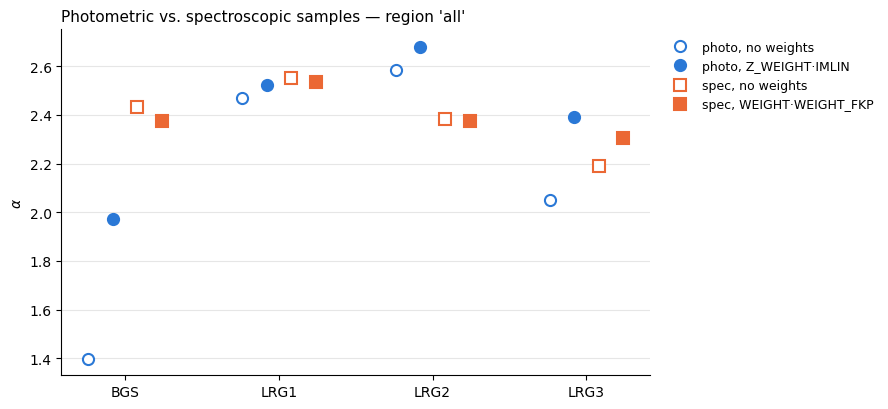

kind            photo                          spec                  
weight     no weights Z_WEIGHT·IMLIN     no weights WEIGHT·WEIGHT_FKP
sample                                                               
BGS     1.398 ± 0.003  1.972 ± 0.006  2.434 ± 0.012     2.377 ± 0.013
LRG1    2.471 ± 0.010  2.525 ± 0.010  2.550 ± 0.013     2.534 ± 0.014
LRG2    2.583 ± 0.008  2.679 ± 0.008  2.385 ± 0.010     2.376 ± 0.011
LRG3    2.049 ± 0.006  2.390 ± 0.008  2.192 ± 0.009     2.306 ± 0.011

In [11]:
CMP_REGION = "all"
CMP_SAMPLES = ["BGS", "LRG1", "LRG2", "LRG3"]
CMP_SERIES = [  # (kind, weight, label, colour, filled)
    ("photo", "none",        "photo, no weights",       "#2a78d6", False),
    ("photo", "weight_phot", "photo, Z_WEIGHT·IMLIN",   "#2a78d6", True),
    ("spec",  "none",        "spec, no weights",        "#eb6834", False),
    ("spec",  "weight_FKP",  "spec, WEIGHT·WEIGHT_FKP", "#eb6834", True),
]

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(CMP_SAMPLES))
for off, (kind, weight, label, color, filled) in zip(np.linspace(-0.24, 0.24, len(CMP_SERIES)), CMP_SERIES):
    sub = df[(df["kind"] == kind) & (df["weight"] == weight) & (df["region"] == CMP_REGION)].set_index("sample").loc[CMP_SAMPLES]
    ax.errorbar(x + off, sub["alpha"], yerr=sub["alpha_error"], linestyle="none", marker="o" if kind == "photo" else "s",
                markersize=8, elinewidth=1.5, capsize=0, color=color, markeredgecolor=color, markeredgewidth=1.5,
                markerfacecolor=color if filled else "white", label=label)
ax.set_xticks(x)
ax.set_xticklabels(CMP_SAMPLES)
ax.set_ylabel(r"$\alpha$")
ax.set_title(f"Photometric vs. spectroscopic samples — region '{CMP_REGION}'", loc="left", fontsize=11)
ax.grid(axis="y", color="0.9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

cmp_cols = [(kind, WEIGHT_LABELS[w]) for kind, w, *_ in CMP_SERIES]
(df[(df["region"] == CMP_REGION) & df["sample"].isin(CMP_SAMPLES)]
   .assign(entry=lambda d: [f"{a:.3f} ± {e:.3f}" for a, e in zip(d["alpha"], d["alpha_error"])],
           weight=lambda d: d["weight"].map(WEIGHT_LABELS),
           sample=lambda d: pd.Categorical(d["sample"], CMP_SAMPLES))
   .pivot_table(index="sample", columns=["kind", "weight"], values="entry", aggfunc="first", observed=True)
   .reindex(columns=pd.MultiIndex.from_tuples(cmp_cols, names=["kind", "weight"])))

## Are the regions consistent?

(α_region − α_all) / σ_region for every sample × region, with the sample's weights (`HEAT_WEIGHT`). Blue = lower than the full footprint, red = higher; grey = not measured (`des_photo-only` is photo-only). Regions are subsets of `all`, so the true significance of a difference is slightly larger than shown. A broken selection shows up as a whole row or column far off. The BGS_phot north bug was a 96 % deficit, i.e. hundreds of σ. A few-σ north vs. south+DES pattern is expected: the imaging (BASS/MzLS vs. DECaLS/DES) and, for LRGs, the target-selection boundaries differ, so α can legitimately differ by a few percent.

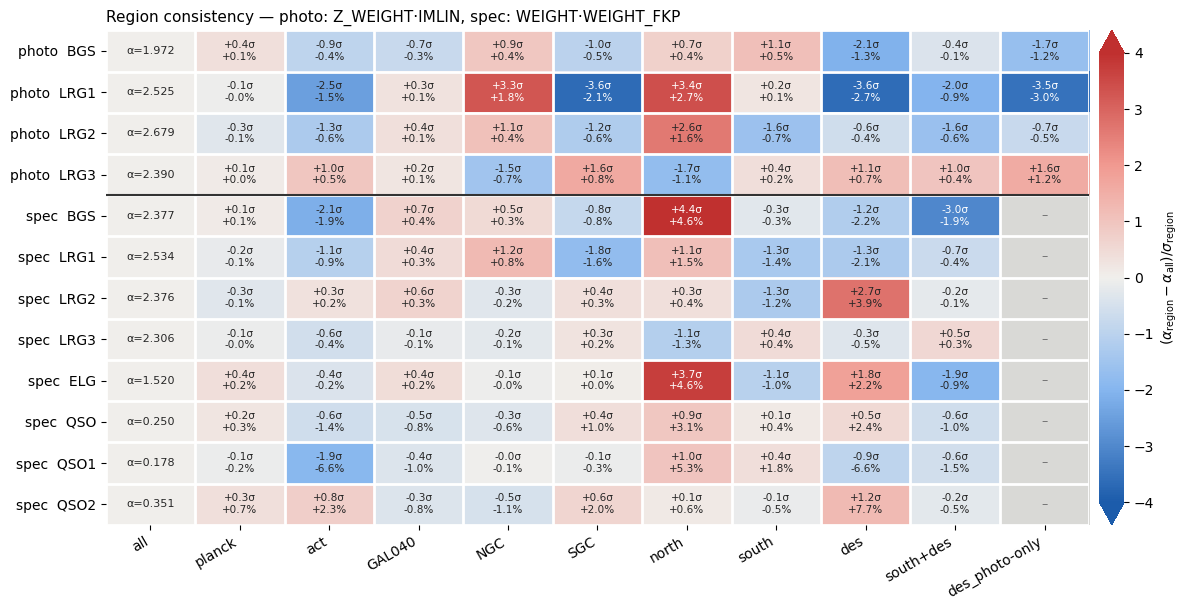

In [12]:
from matplotlib.colors import LinearSegmentedColormap

HEAT_WEIGHT = {"photo": "weight_phot", "spec": "weight_FKP"}
REGION_ORDER = ["all", "planck", "act", "GAL040", "NGC", "SGC", "north", "south", "des", "south+des", "des_photo-only"]
HEAT_LIMIT = 4.0   # colour scale saturates at +-4 sigma

sub = df[df["weight"] == df["kind"].map(HEAT_WEIGHT)].copy()
alpha_all = sub[sub["region"] == "all"].set_index(["kind", "sample"])["alpha"]
sub["nsigma"] = (sub["alpha"] - sub.set_index(["kind", "sample"]).index.map(alpha_all)) / sub["alpha_error"]
sub["frac"] = sub["alpha"] / sub.set_index(["kind", "sample"]).index.map(alpha_all) - 1

rows = [(k, s) for k in ["photo", "spec"] for s in SAMPLE_ORDER if (k, s) in alpha_all.index]
nsig = sub.pivot_table(index=["kind", "sample"], columns="region", values="nsigma").reindex(index=rows, columns=REGION_ORDER)
frac = sub.pivot_table(index=["kind", "sample"], columns="region", values="frac").reindex(index=rows, columns=REGION_ORDER)

# diverging: blue <- neutral grey -> red
cmap = LinearSegmentedColormap.from_list("blue_grey_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f19a91", "#c0302f"])
cmap.set_bad("#d9d9d6")

fig, ax = plt.subplots(figsize=(12, 6.2))
im = ax.imshow(np.ma.masked_invalid(nsig.values), cmap=cmap, vmin=-HEAT_LIMIT, vmax=HEAT_LIMIT, aspect="auto")
for i in range(nsig.shape[0]):
    for j in range(nsig.shape[1]):
        v, fr = nsig.values[i, j], frac.values[i, j]
        if np.isnan(v):
            ax.text(j, i, "–", ha="center", va="center", fontsize=9, color="0.45")
        elif REGION_ORDER[j] == "all":
            ax.text(j, i, f"α={alpha_all.loc[rows[i]]:.3f}", ha="center", va="center", fontsize=8, color="0.15")
        else:
            ax.text(j, i, f"{v:+.1f}σ\n{100*fr:+.1f}%", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v) > 0.7 * HEAT_LIMIT else "0.15")
# white gaps between cells
ax.set_xticks(np.arange(len(REGION_ORDER) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(rows) + 1) - 0.5, minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", length=0)
ax.axhline(sum(k == "photo" for k, _ in rows) - 0.5, color="0.2", linewidth=1.5)   # photo | spec separator
ax.set_xticks(range(len(REGION_ORDER)))
ax.set_xticklabels(REGION_ORDER, rotation=30, ha="right")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{k}  {s}" for k, s in rows])
for side in ax.spines.values():
    side.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, extend="both")
cbar.set_label(r"$(\alpha_{\rm region} - \alpha_{\rm all}) / \sigma_{\rm region}$")
cbar.outline.set_visible(False)
ax.set_title(f"Region consistency — photo: {WEIGHT_LABELS[HEAT_WEIGHT['photo']]}, spec: {WEIGHT_LABELS[HEAT_WEIGHT['spec']]}",
             loc="left", fontsize=11)
fig.tight_layout()
plt.show()